<a href="https://colab.research.google.com/github/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/blob/main/L06_Red_Neuronal_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa: Predicción del Precio de Vivienda
Dataset: `Housing.csv` — variable de interés: `price`.

## 1. Exploración del conjunto de datos y sus variables

Paso 1. Importamos la paquetería necesaria.

In [1]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K

# Utilidades de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Paleta de colores consistente para todas las gráficas
COLOR_TRAIN = '#2a78d6'   # azul
COLOR_VAL   = '#eb6834'   # naranja
COLOR_AUX   = '#1baf7a'   # aqua

np.random.seed(42)
tf.random.set_seed(42)

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Paso 2. Descargamos y cargamos el dataset.

In [2]:
!rm -f "Housing.csv"
!wget -q "https://raw.githubusercontent.com/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/main/Datasets/Housing.csv" -O "Housing.csv"

dataset = pd.read_csv("Housing.csv")
dataset.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Paso 3. Exploramos la estructura, los tipos de dato y las estadísticas descriptivas.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [4]:
dataset.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


Revisamos la distribución de la variable de interés y su relación con el área construida.

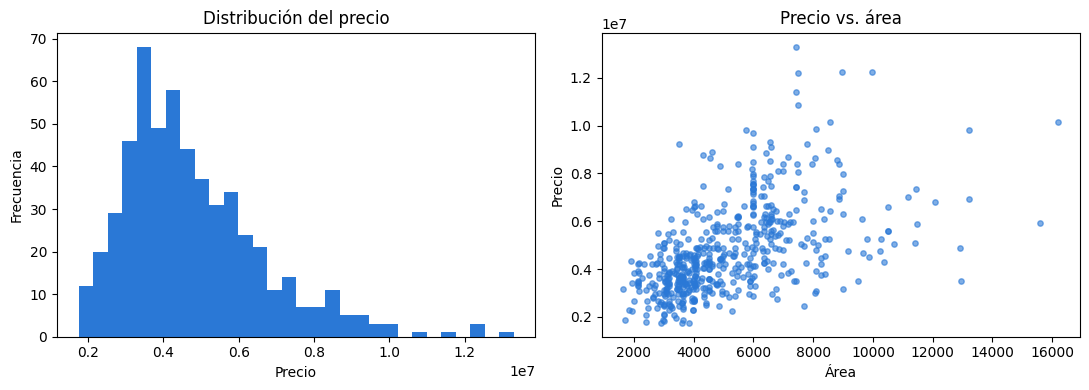

In [5]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.hist(dataset['price'], bins=30, color=COLOR_TRAIN)
plt.title('Distribución del precio')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
plt.scatter(dataset['area'], dataset['price'], color=COLOR_TRAIN, s=15, alpha=0.6)
plt.title('Precio vs. área')
plt.xlabel('Área')
plt.ylabel('Precio')

plt.tight_layout()
plt.show()

## 2. Limpieza del conjunto de datos y codificación de variables

Paso 4. Revisamos valores faltantes.

In [6]:
dataset.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Paso 5. Codificamos las variables categóricas binarias (`yes`/`no`) como 1/0, y aplicamos codificación one-hot a `furnishingstatus`, que tiene tres categorías.

In [7]:
binarias = ['mainroad', 'guestroom', 'basement', 'hotwaterheating',
            'airconditioning', 'prefarea']
for col in binarias:
    dataset[col] = (dataset[col] == 'yes').astype(int)

dataset = pd.get_dummies(dataset, columns=['furnishingstatus'], drop_first=True)
dataset = dataset.astype({c: int for c in dataset.columns if dataset[c].dtype == bool})

print(dataset.dtypes)
dataset.head()

price                              int64
area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
mainroad                           int64
guestroom                          int64
basement                           int64
hotwaterheating                    int64
airconditioning                    int64
parking                            int64
prefarea                           int64
furnishingstatus_semi-furnished    int64
furnishingstatus_unfurnished       int64
dtype: object


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


## 3. Variables de entrada y variable de salida

Paso 6. La variable de salida es `price`; el resto de las columnas son las variables de entrada.

In [8]:
x = np.asanyarray(dataset.drop(columns=['price']))
y = np.asanyarray(dataset[['price']])
print(x.shape)
print(y.shape)

(545, 13)
(545, 1)


## 4. Normalización y partición del conjunto de datos

Paso 7. Estandarizamos tanto las variables de entrada como la variable de salida (el precio tiene una escala muy grande, lo que dificulta el entrenamiento de la red si no se normaliza) y particionamos en entrenamiento (80%) y prueba (20%).

In [9]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

x = scaler_x.fit_transform(x)
y = scaler_y.fit_transform(y)

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42)

print(xtrain.shape, xtest.shape)

(436, 13) (109, 13)


## 5. Diseño de la red neuronal

Paso 8. Diseñamos una red densa con dos capas ocultas para resolver el problema de regresión. La capa de salida tiene una sola neurona con activación lineal. Además de la métrica MAE, definimos la métrica R² para monitorear qué tan bien se explica la varianza del precio.

In [10]:
def r2score(y_true, y_pred):
    SS_res = K.sum(K.square(y_true - y_pred))
    SS_tot = K.sum(K.square(y_true - K.mean(y_true)))
    return 1 - SS_res / (SS_tot + K.epsilon())

def build_model(n_inputs, hidden1=64, hidden2=32, dropout=0.2, lr=1e-3):
    model = keras.Sequential()
    model.add(keras.layers.Dense(hidden1, activation='relu', input_shape=[n_inputs]))
    model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(hidden2, activation='relu'))
    model.add(keras.layers.Dense(1, activation='linear'))

    model.compile(loss='mean_squared_error',
                  optimizer=keras.optimizers.Adam(learning_rate=lr),
                  metrics=[keras.metrics.MAE, r2score])
    return model

model = build_model(x.shape[1])
model.summary()

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento de la red y curvas de aprendizaje

Paso 9. Entrenamos la red con los hiperparámetros base.

In [11]:
history = model.fit(xtrain, ytrain,
                     batch_size=16, epochs=200,
                     validation_data=(xtest, ytest), verbose=0)
print('Última pérdida de validación:', history.history['val_loss'][-1])

Última pérdida de validación: 0.5344462394714355


Paso 10. Graficamos la evolución del entrenamiento a través de las épocas.

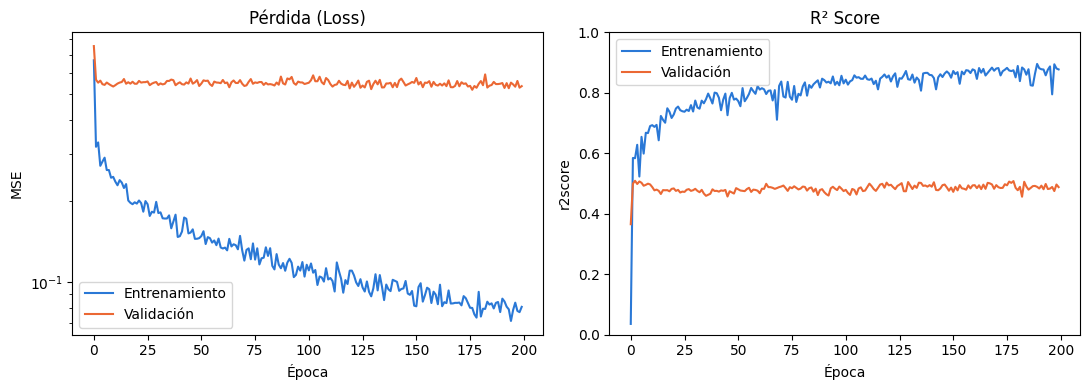

In [12]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.title('Pérdida (Loss)')
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.plot(hist['epoch'], hist['loss'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_loss'], color=COLOR_VAL, label='Validación')
    plt.yscale('log')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.title('R² Score')
    plt.xlabel('Época')
    plt.ylabel('r2score')
    plt.plot(hist['epoch'], hist['r2score'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_r2score'], color=COLOR_VAL, label='Validación')
    plt.ylim([0, 1])
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

## 7. Búsqueda de hiperparámetros

Paso 11. Probamos distintas combinaciones de número de neuronas, `dropout` y tasa de aprendizaje, entrenando cada combinación con `EarlyStopping` y comparando el R² sobre el conjunto de validación.

In [13]:
configs = [
    dict(hidden1=32, hidden2=16, dropout=0.1, lr=1e-3),
    dict(hidden1=64, hidden2=32, dropout=0.2, lr=1e-3),
    dict(hidden1=64, hidden2=32, dropout=0.3, lr=5e-4),
    dict(hidden1=128, hidden2=64, dropout=0.2, lr=1e-3),
    dict(hidden1=128, hidden2=32, dropout=0.3, lr=5e-4),
]

resultados = []
for cfg in configs:
    es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=20,
                                        restore_best_weights=True)
    m = build_model(x.shape[1], **cfg)
    h = m.fit(xtrain, ytrain, batch_size=16, epochs=400,
              validation_data=(xtest, ytest), verbose=0, callbacks=[es])
    val_loss = min(h.history['val_loss'])
    val_r2 = max(h.history['val_r2score'])
    resultados.append({**cfg, 'val_loss': val_loss, 'val_r2score': val_r2,
                        'epochs_entrenadas': len(h.epoch)})

resultados_df = pd.DataFrame(resultados).sort_values('val_r2score', ascending=False)
resultados_df

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,hidden1,hidden2,dropout,lr,val_loss,val_r2score,epochs_entrenadas
1,64,32,0.2,0.0010,0.449074,0.564610,33
4,128,32,0.3,0.0005,0.469819,0.538552,50
2,64,32,0.3,0.0005,0.489480,0.534672,52
0,32,16,0.1,0.0010,0.517251,0.510850,32
3,128,64,0.2,0.0010,0.502252,0.506950,38


Paso 12. Reentrenamos el modelo final con la mejor combinación de hiperparámetros encontrada.

Mejores hiperparámetros encontrados: {'hidden1': 64, 'hidden2': 32, 'dropout': np.float64(0.2), 'lr': np.float64(0.001)}


/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


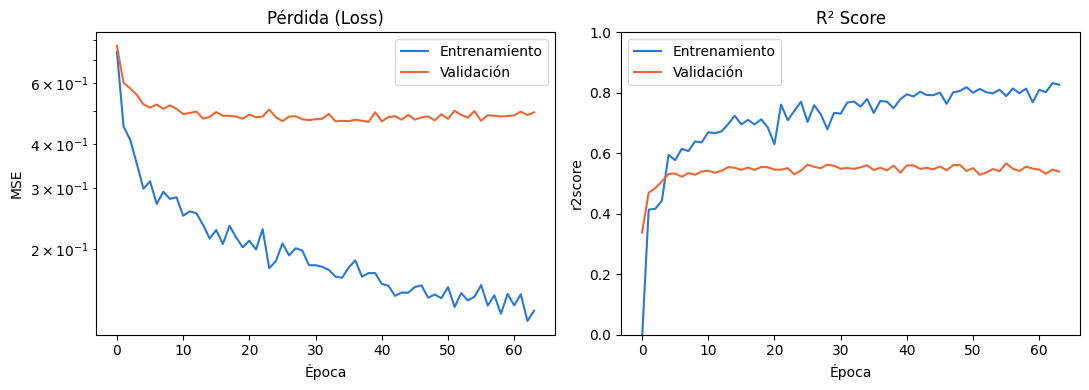

In [14]:
best_cfg = {k: resultados_df.iloc[0][k] for k in ['hidden1', 'hidden2', 'dropout', 'lr']}
best_cfg['hidden1'] = int(best_cfg['hidden1'])
best_cfg['hidden2'] = int(best_cfg['hidden2'])
print('Mejores hiperparámetros encontrados:', best_cfg)

es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=25,
                                    restore_best_weights=True)
final_model = build_model(x.shape[1], **best_cfg)
history_final = final_model.fit(xtrain, ytrain, batch_size=16, epochs=500,
                                 validation_data=(xtest, ytest), verbose=0,
                                 callbacks=[es])
plot_history(history_final)

## 8. Métricas de desempeño

Paso 13. Calculamos las métricas de regresión sobre el conjunto de prueba, revirtiendo la normalización para expresarlas en la escala original del precio.

In [15]:
y_pred_scaled = final_model.predict(xtest, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_real = scaler_y.inverse_transform(ytest)

mae = mean_absolute_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
r2 = r2_score(y_real, y_pred)

print(f'MAE  : {mae:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 958,764.47
RMSE : 1,274,070.54
R2   : 0.6789


Paso 14. Visualizamos el precio predicho contra el precio real.

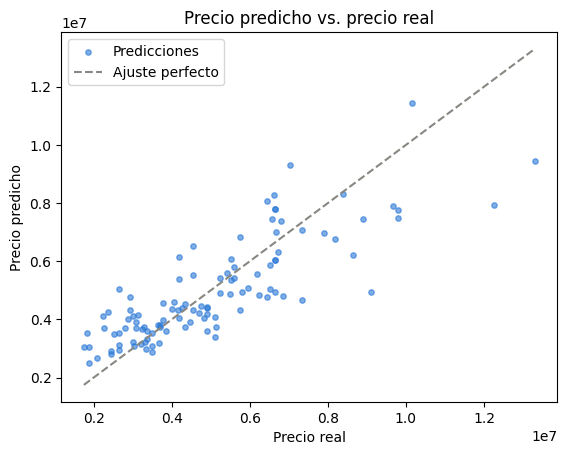

In [16]:
plt.figure()
plt.scatter(y_real, y_pred, color=COLOR_TRAIN, s=15, alpha=0.6, label='Predicciones')
lims = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='#898781', label='Ajuste perfecto')
plt.title('Precio predicho vs. precio real')
plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.legend()
plt.show()